# Train a convolutional neural network

Train a small CNN to read handwritten digits. It uses the same layers as the site's draw-a-digit model, but this notebook trains for only three epochs and skips augmentation to keep the run short. Run the cells in order with **Shift + Enter**.

In [1]:
# Running locally? If TensorFlow is missing, uncomment the next line. Colab already has it.
# %pip install -q tensorflow
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)

## Load and look at MNIST

[MNIST](https://keras.io/api/datasets/mnist/) has 60,000 training images and 10,000 test images. Each is a 28 × 28 grid with a light digit on a dark background. The dataset is available under CC BY-SA 3.0 (Yann LeCun and Corinna Cortes). Divide the pixel values by 255 to scale them to 0–1, then add a final dimension for the single grayscale channel.

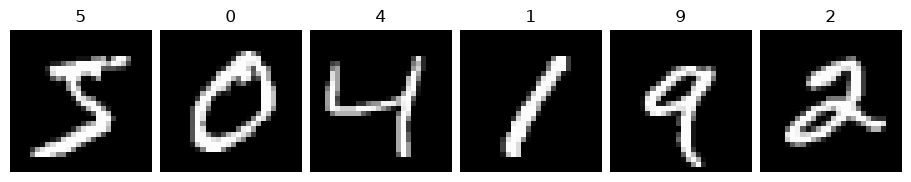

In [2]:
(train_pixels, train_labels), (test_pixels, test_labels) = keras.datasets.mnist.load_data()

fig, axes = plt.subplots(1, 6, figsize=(9, 2), layout="constrained")
for ax, pixels, label in zip(axes, train_pixels[:6], train_labels[:6]):
    ax.imshow(pixels, cmap="gray", vmin=0, vmax=255)
    ax.set_title(str(label))
    ax.axis("off")
plt.show()

train_images = train_pixels[..., np.newaxis].astype(np.float32) / 255.0
test_images = test_pixels[..., np.newaxis].astype(np.float32) / 255.0

## Build the CNN

A convolution slides a learned 3 × 3 filter across the image and scores each patch. ReLU sets negative scores to zero, leaving one feature map per filter. Max pooling keeps the strongest response in each 2 × 2 block. The second convolution and pool leave a 5 × 5 × 16 grid. Flattening turns it into 400 values for the dense layers. The final softmax gives ten probabilities that add up to one.

In [3]:
model = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(8, 3, padding="valid", activation="relu", data_format="channels_last", name="conv1"),
    layers.MaxPooling2D(2, data_format="channels_last", name="pool1"),
    layers.Conv2D(16, 3, padding="valid", activation="relu", data_format="channels_last", name="conv2"),
    layers.MaxPooling2D(2, data_format="channels_last", name="pool2"),
    layers.Flatten(data_format="channels_last"),
    layers.Dense(64, activation="relu", name="dense1"),
    layers.Dense(10, activation="softmax", name="dense2"),
], name="mnist_cnn")
model.summary()

Model: "mnist_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 26, 26, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 13, 13, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 11, 11, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 64)             │        25,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense2 (Dense)                  │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,562 (107.66 KB)

 Trainable params: 27,562 (107.66 KB)

 Non-trainable params: 0 (0.00 B)

## Train and check

Adam updates the weights after each batch of 128 images. The loss penalizes low probability on the correct digit. After three passes through the training data, measure accuracy on the test set. The confusion matrix counts correct predictions on the diagonal and mistakes off it: read across a row to see which digits the model predicted for that true label.

Epoch 1/3


469/469 - 5s - 10ms/step - accuracy: 0.8964 - loss: 0.3629


Epoch 2/3


469/469 - 3s - 7ms/step - accuracy: 0.9704 - loss: 0.0982


Epoch 3/3


469/469 - 3s - 7ms/step - accuracy: 0.9779 - loss: 0.0723


Test accuracy: 98.03%


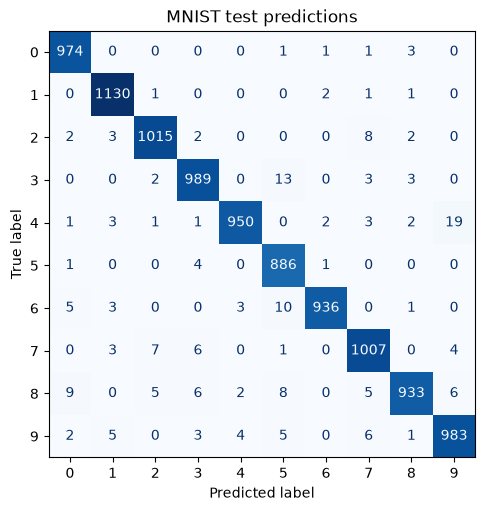

In [4]:
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.fit(train_images, train_labels, epochs=3, batch_size=128, verbose=2)
_, accuracy = model.evaluate(test_images, test_labels, batch_size=128, verbose=0)
print(f"Test accuracy: {accuracy:.2%}")

test_probs = model.predict(test_images, batch_size=128, verbose=0)
fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
ConfusionMatrixDisplay.from_predictions(
    test_labels, test_probs.argmax(axis=1), ax=ax, cmap="Blues", colorbar=False, values_format="d"
)
ax.set_title("MNIST test predictions")
plt.show()

## See it

The top row shows the eight learned filters. Blue weights are negative and red weights are positive. Below each filter, bright spots show where it responds strongly to this test digit after ReLU. The bar chart shows the final prediction from the whole network. Change `sample_index` and see which maps light up for a different digit.

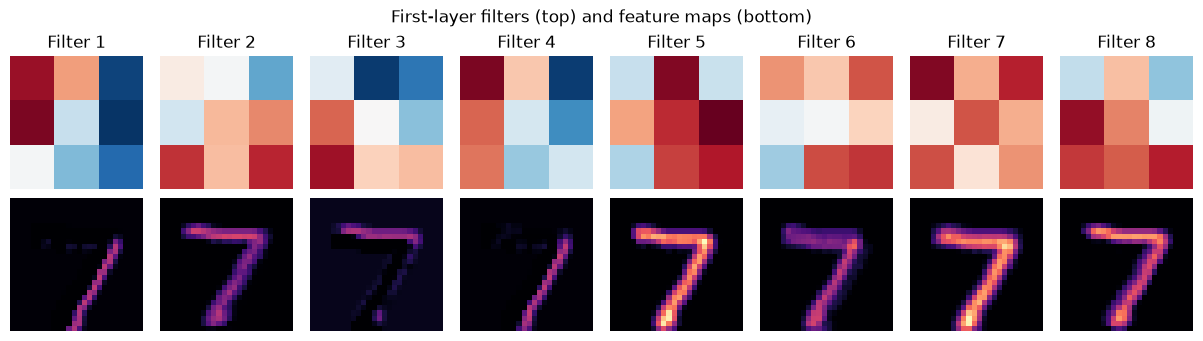

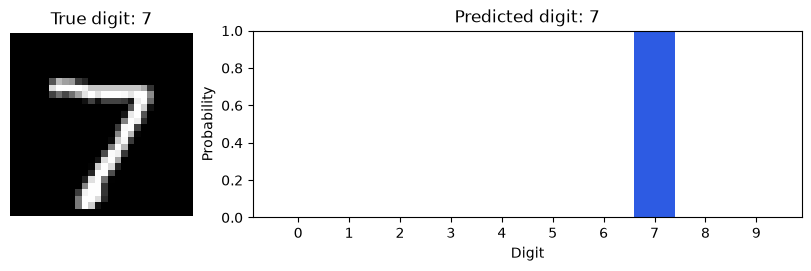

In [5]:
sample_index = 0
conv1 = model.get_layer("conv1")
kernels, _ = conv1.get_weights()
feature_maps = conv1(test_images[sample_index:sample_index + 1]).numpy()[0]
weight_limit = np.abs(kernels).max()
response_limit = feature_maps.max()

fig, axes = plt.subplots(2, 8, figsize=(12, 3.3), layout="constrained")
for channel, (filter_ax, map_ax) in enumerate(zip(*axes)):
    filter_ax.imshow(kernels[:, :, 0, channel], cmap="RdBu_r", interpolation="nearest",
                     vmin=-weight_limit, vmax=weight_limit)
    filter_ax.set_title(f"Filter {channel + 1}")
    map_ax.imshow(feature_maps[:, :, channel], cmap="magma", vmin=0, vmax=response_limit)
    filter_ax.set_axis_off()
    map_ax.set_axis_off()
fig.suptitle("First-layer filters (top) and feature maps (bottom)")
plt.show()

probabilities = test_probs[sample_index]
fig, (image_ax, prob_ax) = plt.subplots(1, 2, figsize=(8, 2.6),
                                       width_ratios=[1, 3], layout="constrained")
image_ax.imshow(test_pixels[sample_index], cmap="gray", vmin=0, vmax=255)
image_ax.set_title(f"True digit: {test_labels[sample_index]}")
image_ax.set_axis_off()
prob_ax.bar(range(10), probabilities, color="#2d5be3")
prob_ax.set(title=f"Predicted digit: {probabilities.argmax()}", xlabel="Digit",
            ylabel="Probability", xticks=range(10), ylim=(0, 1))
plt.show()